# Model Evaluation & Bayesian ROPE Analysis

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import sys

sys.path.append("..")
from part1.analysis import BenavoliCorrelatedT

Path("results").mkdir(exist_ok=True)

with open("results/tuning_results.json") as f:
    results = json.load(f)

## 1. Cross-Validation Results Across All 9 Systems

**Distribution of 5-fold cross-validation accuracies:**

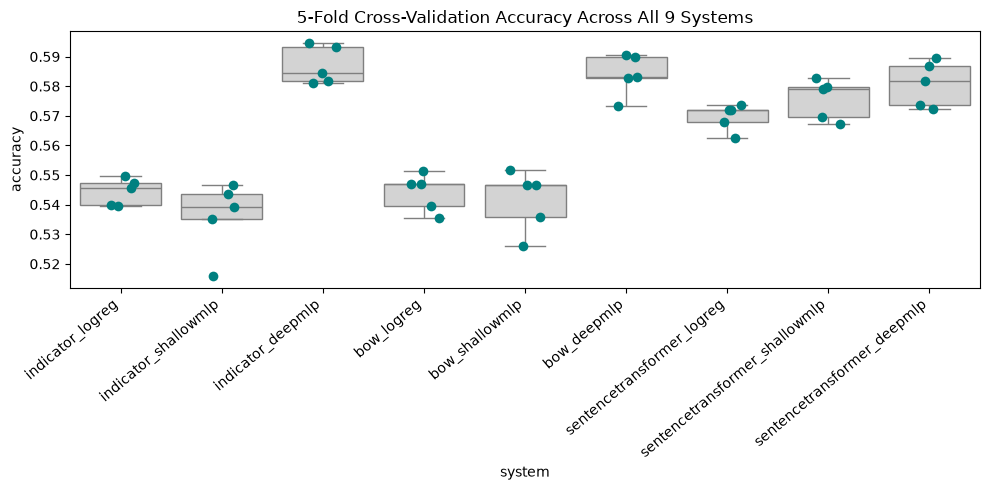

In [2]:
rows = []
for model_name, data in results.items():
    for fold_idx, acc in enumerate(data["accuracies"]):
        parts = model_name.split("_")
        encoder = parts[0]
        classifier = parts[1]
        rows.append({
            "system": model_name,
            "encoder": encoder,
            "classifier": classifier,
            "fold": fold_idx,
            "accuracy": acc
        })

df_results = pd.DataFrame(rows)

plt.figure(figsize=(10, 5))
sns.boxplot(data=df_results, x="system", y="accuracy", color="lightgray", showfliers=False)
sns.stripplot(data=df_results, x="system", y="accuracy", color="teal", size=7, jitter=0.15)
plt.xticks(rotation=40, ha="right")
plt.title("5-Fold Cross-Validation Accuracy Across All 9 Systems")
plt.tight_layout()
plt.savefig("results/all_systems_cv_boxplot.png", dpi=300)
plt.show()

Results:
- Indicator and BoW architectures struggle with word 
swapping.
- SentenceTransformer lifts linear models from 54.4% to 57.0%.
- DeepMLP peaks around 58.5%, where its non-linear capacity equalizes all three representations between 58.1% and 58.7%.

## 2. Bayesian Correlated t-Tests

We use the Benavoli Correlated t-test BenavoliCorrelatedT with a Region of Practical Equivalence (ROPE = $\pm 0.01$). On PAWS, a $1\%$ difference corresponds to roughly 80–100 sentence pairs. improvements below this threshold are considered practically equivalent as they do not justify the added latency and memory overhead of dense transformer embeddings over simpler models.

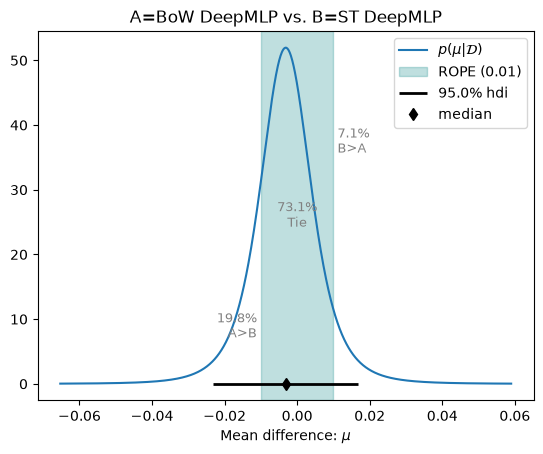

P(BoW wins): 0.198, P(Tie/ROPE): 0.731, P(ST wins): 0.071
Posterior Mean Difference: -0.0032
Effect size: -0.437


In [3]:
rope = 0.01

bow_accs = results["bow_deepmlp"]["accuracies"]
st_accs = results["sentencetransformer_deepmlp"]["accuracies"]

comp_rep = BenavoliCorrelatedT(bow_accs, st_accs, names=["BoW DeepMLP", "ST DeepMLP"])
fig, ax = comp_rep.plot(rope_param=rope)
plt.savefig("results/rope_bow_vs_st.png", dpi=300)
plt.show()

p_A, p_tie, p_B = comp_rep.probs(rope)
print(f"P(BoW wins): {p_A:.3f}, P(Tie/ROPE): {p_tie:.3f}, P(ST wins): {p_B:.3f}")
print(f"Posterior Mean Difference: {comp_rep.mean_diff:.4f}")
print(f"Effect size: {comp_rep.effect_size:.3f}")

### Comparison 1: BoW DeepMLP vs. ST DeepMLP

- **$P(\text{Tie / ROPE}) = 73.1\%$**, $P(\text{BoW}) = 19.8\%$, $P(\text{ST}) = 7.1\%$
- Result: The two models are practically equivalent because DeepMLP's hidden units learn feature combinations from Bag-of-Words that match the performance of frozen transformer embeddings.

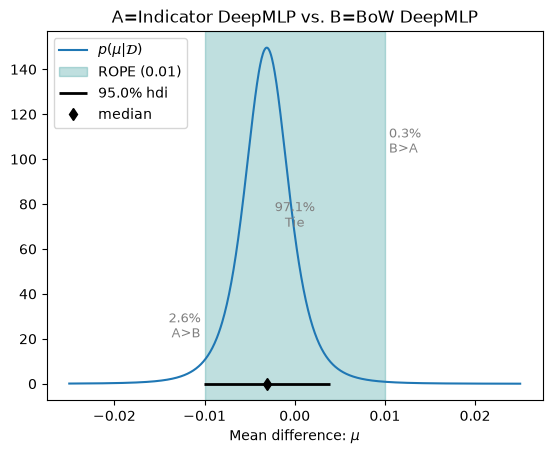

P(Indicator wins): 0.026, P(Tie/ROPE): 0.971, P(BoW wins): 0.003


In [4]:
ind_accs = results["indicator_deepmlp"]["accuracies"]
bow_accs = results["bow_deepmlp"]["accuracies"]

comp_surf = BenavoliCorrelatedT(ind_accs, bow_accs, names=["Indicator DeepMLP", "BoW DeepMLP"])
fig, ax = comp_surf.plot(rope_param=rope)
plt.savefig("results/rope_indicator_vs_bow.png", dpi=300)
plt.show()

p_A, p_tie, p_B = comp_surf.probs(rope)
print(f"P(Indicator wins): {p_A:.3f}, P(Tie/ROPE): {p_tie:.3f}, P(BoW wins): {p_B:.3f}")

### Comparison 2: Indicator DeepMLP vs. BoW DeepMLP

- **$P(\text{Tie / ROPE}) = 97.1\%$**, $P(\text{Indicator}) = 2.6\%$, $P(\text{BoW}) = 0.3\%$
- Result: The two models are practically equivalent because PAWS sentences are short (around 20 words), meaning words rarely appear more than once and word counts provide no extra signal over simple word presence.

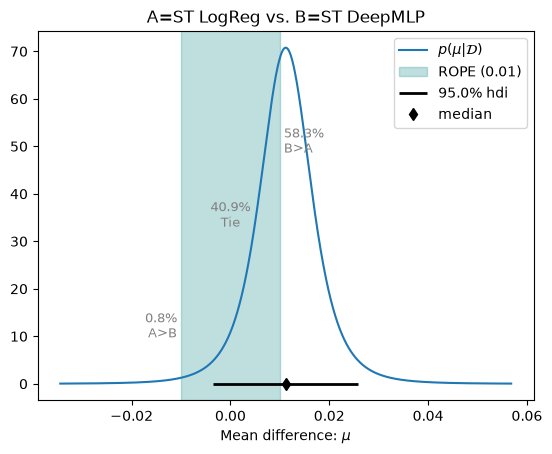

P(LogReg wins): 0.008, P(Tie/ROPE): 0.409, P(DeepMLP wins): 0.583


In [5]:
lr_accs = results["sentencetransformer_logreg"]["accuracies"]
deep_accs = results["sentencetransformer_deepmlp"]["accuracies"]

comp_arch = BenavoliCorrelatedT(lr_accs, deep_accs, names=["ST LogReg", "ST DeepMLP"])
fig, ax = comp_arch.plot(rope_param=rope)
plt.savefig("results/rope_logreg_vs_deepmlp.png", dpi=300)
plt.show()

p_A, p_tie, p_B = comp_arch.probs(rope)
print(f"P(LogReg wins): {p_A:.3f}, P(Tie/ROPE): {p_tie:.3f}, P(DeepMLP wins): {p_B:.3f}")

### Comparison 3: ST LogReg vs. ST DeepMLP

- **$P(\text{DeepMLP wins}) = 58.3\%$**, $P(\text{Tie}) = 40.9\%$, $P(\text{LogReg}) = 0.8\%$
- Result: $P(\text{DeepMLP} \ge \text{LogReg}) = 99.2\%$. Adding non-linear layers improves performance on dense embeddings which gives DeepMLP a clear edge over logistic regression.